# Домашнее задание №2. Аудит A/B-эксперимента

Единица анализа — пользователь. Плановое распределение — 50/50, уровень значимости — 0,05. Первичная метрика — конверсия. Guardrail — частота ошибок.  
Для повторного запуска поместите CSV рядом с ноутбуком. Без CSV код воспроизводит его с зафиксированным seed. Генерация сохраняет порядок и параметры случайных вызовов из задания.

In [1]:
from hashlib import sha256
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

MY_SEED = 1696087
DATA_PATH = Path(f"exp_data_seed_{MY_SEED}.csv")
ALPHA = 0.05
GROUPS = ["control", "test"]

In [2]:
def generate_experiment():
    np.random.seed(MY_SEED)
    n_users = np.random.randint(1000, 10000, size=1)[0]
    true_effect = 0
    expected_ratio = 0.5
    
    time_of_entry = np.random.uniform(0, 1, n_users)  # время от 0 до 1
    
    # В test группе делаем сдвиг во времени (позднее включение)
    
    variant = np.where(time_of_entry > 0.4, 'test', 'control')  # не 50/50
    
    
    # Попробуем сымитировать  SRM: сделаем неравными группы (например, 55/45)
    
    # Переопределим variant с нужной пропорцией
    
    p_ = np.random.uniform(low=0.4001, high=0.599999, size=1)[0]
    
    variant = np.random.choice(['control', 'test'], size=n_users, p=[p_, 1-p_])
    
    
    # ----- НАРУШЕНИЕ 2: confounder (погода/день недели влияет и на участие, и на результат) -----
    
    # Допустим, есть скрытая переменная "weekend" (0/1), которая увеличивает конверсию
    
    weekend = np.random.binomial(1, 0.3, n_users)
    
    # В тестовой группе больше weekend-пользователей
    
    p_ = np.random.uniform(low=0.40001, high=0.499999, size=1)[0]
    
    variant = np.where((variant == 'test') & (weekend == 1), 'test',
                       np.where((variant == 'control') & (weekend == 0), 'control',
                                np.random.choice(['control', 'test'], size=n_users, p=[p_, 1-p_])))  # оставляем некоторую случайность
    
    
    # Конверсия зависит от weekend (истинный эффект фичи = 0)
    
    conversion_prob = 0.1 + 0.05 * weekend
    
    converted = np.random.binomial(1, conversion_prob, n_users)
    
    
    #  ----- НАРУШЕНИЕ 3: множественные проверки и сегментация -----
    
    # Добавим несколько сегментов (платформа: 0,1,2)
    
    p_ = np.random.uniform(low=0.02, high=0.15, size=1)[0]
    
    p_2 = np.random.uniform(low=0.25, high=0.35, size=1)[0]
    
    platform = np.random.choice([0,1,2], size=n_users, p=[1-p_2-p_,p_2,p_])
    
    # В сегменте platform=2 тестовая группа получила искусственный подъём конверсии (ложный сигнал)
    
    converted = np.where((platform == 2) & (variant == 'test'),
                         np.random.binomial(1, 0.2, size=len(converted)),
                         converted)
    
    
    # ----- Guardrail: частота ошибок (должна быть одинаковой, но в test завышена) -----
    
    error_flag = np.zeros(n_users)
    
    error_flag[variant == 'control'] = np.random.binomial(1, 0.02, sum(variant == 'control'))
    
    error_flag[variant == 'test'] = np.random.binomial(1, 0.06, sum(variant == 'test'))
    
    
    # Финальный датафрейм
    
    df = pd.DataFrame({
        'user_id': range(n_users),
        'variant': variant,
        'converted': converted,
        'error_flag': error_flag,
        'weekend': weekend,
        'platform': platform,
        'entry_time': time_of_entry
    })
    return df


if not DATA_PATH.exists():
    generate_experiment().to_csv(DATA_PATH, index=False, lineterminator="\n")

print(f"Seed: {MY_SEED}")
print(f"SHA-256: {sha256(DATA_PATH.read_bytes()).hexdigest()}")

Seed: 1696087
SHA-256: 8f05376073adf1b802886c633669e5b951aaae4e3c4250b8dcb65aca89e52feb


## 1. Загрузка и описание

Проверяем схему, полноту и уникальность пользователей. Конверсия и частота ошибок — доли пользователей с соответствующим признаком.

In [3]:
df = pd.read_csv(DATA_PATH)
required = {"user_id", "variant", "converted", "error_flag", "weekend", "platform", "entry_time"}
if set(df.columns) != required or df.isna().any().any() or not df["user_id"].is_unique:
    raise ValueError("Неверная схема, пропуски или повторные user_id.")
if set(df["variant"]) != set(GROUPS) or set(df["platform"]) != {0, 1, 2}:
    raise ValueError("Отсутствуют группы или уровни платформы.")
for col in ["converted", "error_flag", "weekend"]:
    if not df[col].isin([0, 1]).all():
        raise ValueError(f"{col} должен быть бинарным.")
if not df["entry_time"].between(0, 1).all():
    raise ValueError("Время входа должно быть в диапазоне от 0 до 1 суток.")

summary = df.groupby("variant").agg(
    users=("user_id", "size"),
    conversion=("converted", "mean"),
    error_rate=("error_flag", "mean"),
    weekend_share=("weekend", "mean"),
    entry_time_mean=("entry_time", "mean"),
).reindex(GROUPS)
control = df.loc[df["variant"].eq("control")]
test = df.loc[df["variant"].eq("test")]
print(f"Пользователей: {len(df):,}")
display(summary.round(5))

Пользователей: 4,200


,users,conversion,error_rate,weekend_share,entry_time_mean
variant,,,,,
control,2249,0.10271,0.01556,0.10182,0.50520
test,1951,0.13224,0.05741,0.50333,0.49679


## 2. Проверки до анализа

Для SRM сравниваем размеры групп с планом 50/50 по χ² Пирсона. Для доли выходных используем двусторонний t-тест Уэлча на бинарном признаке. Связь выходных с конверсией проверяем описательно. Причинную роль этой ковариаты устанавливает и сам генератор: weekend влияет на назначение и на базовую вероятность конверсии.

In [4]:
srm = stats.chisquare(summary["users"], f_exp=[len(df) / 2] * 2)
weekend_test = stats.ttest_ind(test["weekend"], control["weekend"], equal_var=False)
weekend_control_conversion = control.groupby("weekend")["converted"].mean()
print(f"χ² = {srm.statistic:.3f}, p = {srm.pvalue:.4g}")
print("SRM обнаружен" if srm.pvalue < ALPHA else "SRM нет")
print(f"Баланс weekend: t = {weekend_test.statistic:.3f}, p = {weekend_test.pvalue:.4g}")
print(f"Конверсия control, будни / выходные: {weekend_control_conversion[0]:.2%} / {weekend_control_conversion[1]:.2%}")

χ² = 21.144, p = 4.261e-06
SRM обнаружен
Баланс weekend: t = 30.896, p = 4.785e-183
Конверсия control, будни / выходные: 9.21% / 19.65%


## 3. Первичная метрика

Двусторонний Z-тест равенства пропорций использует объединённую долю при нулевой гипотезе. 95%-й интервал Уолда для абсолютной разности использует отдельные оценки дисперсии групп. Относительный lift считаем от конверсии control. Решение о значимости для эксперимента откладываем до проверки протокола.

In [5]:
def compare_proportions(test_values, control_values, alternative="two-sided"):
    n_test, n_control = len(test_values), len(control_values)
    p_test, p_control = test_values.mean(), control_values.mean()
    delta = p_test - p_control
    pooled = (test_values.sum() + control_values.sum()) / (n_test + n_control)
    null_se = np.sqrt(pooled * (1 - pooled) * (1 / n_test + 1 / n_control))
    z = delta / null_se if null_se else 0.0
    p_value = stats.norm.sf(z) if alternative == "greater" else 2 * stats.norm.sf(abs(z))
    estimate_se = np.sqrt(p_test * (1 - p_test) / n_test + p_control * (1 - p_control) / n_control)
    half_width = stats.norm.ppf(1 - ALPHA / 2) * estimate_se
    return {
        "n_control": n_control, "n_test": n_test,
        "control_%": 100 * p_control, "test_%": 100 * p_test,
        "delta_п.п.": 100 * delta,
        "lift_%": 100 * delta / p_control if p_control else np.nan,
        "ДИ_низ_п.п.": 100 * (delta - half_width),
        "ДИ_верх_п.п.": 100 * (delta + half_width),
        "p": p_value,
    }


primary = compare_proportions(test["converted"], control["converted"])
display(pd.DataFrame([primary], index=["Конверсия"]).round(6))

,n_control,n_test,control_%,test_%,delta_п.п.,lift_%,ДИ_низ_п.п.,ДИ_верх_п.п.,p
Конверсия,2249,1951,10.271232,13.223988,2.952756,28.747828,0.994786,4.910726,0.002924


## 4. Проверки протокола

Для guardrail используем односторонний Z-тест: проверяем рост частоты ошибок в test. Для платформ считаем три двусторонних теста и корректируем p-value по Бонферрони. Интервалы в таблице относятся к отдельным сравнениям.

Для проверки временного дисбаланса используем двусторонний U-тест Манна–Уитни и график накопленных долей. Даже при временном сдвиге для вывода о peeking нужны журнал промежуточных проверок, динамика p-value и правило остановки.

Остановить тест
Время входа, U = 2,156,230, p = 0.3365


,n_control,n_test,control_%,test_%,delta_п.п.,lift_%,ДИ_низ_п.п.,ДИ_верх_п.п.,p
Ошибки,2249,1951,1.55625,5.74065,4.1844,268.8775,3.0324,5.3364,9.25e-14


,n_control,n_test,control_%,test_%,delta_п.п.,lift_%,ДИ_низ_п.п.,ДИ_верх_п.п.,p,p Бонферрони
platform,,,,,,,,,,
0,1322,1137,10.816944,11.873351,1.056407,9.766223,-1.461212,3.574025,0.409477,1.000000
1,646,564,9.442724,12.588652,3.145928,33.315894,-0.400872,6.692728,0.079936,0.239807
2,281,250,9.608541,20.800000,11.191459,116.474074,5.093390,17.289529,0.000298,0.000893


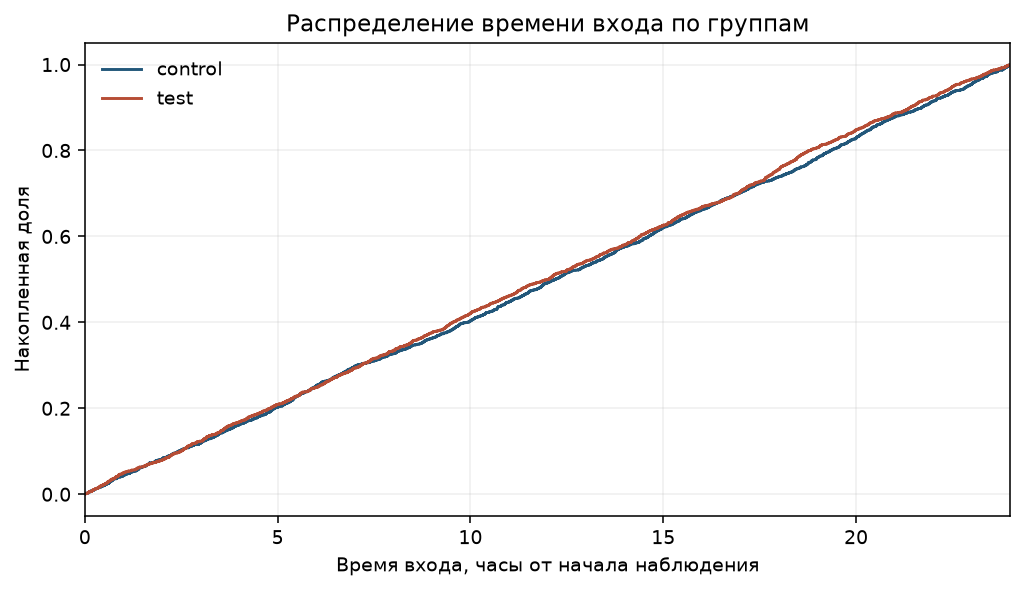

In [6]:
guardrail = compare_proportions(test["error_flag"], control["error_flag"], alternative="greater")
guardrail_table = pd.DataFrame([guardrail], index=["Ошибки"]).round(5)
guardrail_table["p"] = f"{guardrail['p']:.3g}"
display(guardrail_table)
print("Остановить тест" if guardrail["p"] < ALPHA else "Порог остановки по ошибкам не достигнут")

segments = {}
for platform, subset in df.groupby("platform"):
    segments[platform] = compare_proportions(
        subset.loc[subset["variant"].eq("test"), "converted"],
        subset.loc[subset["variant"].eq("control"), "converted"],
    )
segment_results = pd.DataFrame.from_dict(segments, orient="index").rename_axis("platform")
segment_results["p Бонферрони"] = (segment_results["p"] * len(segment_results)).clip(upper=1)
display(segment_results.round(6))

entry_test = stats.mannwhitneyu(test["entry_time"], control["entry_time"], alternative="two-sided")
print(f"Время входа, U = {entry_test.statistic:,.0f}, p = {entry_test.pvalue:.4g}")
fig, ax = plt.subplots(figsize=(7.2, 4.1), layout="constrained")
for group, color in zip(GROUPS, ["#22577A", "#B64D35"]):
    hours = np.sort(24 * df.loc[df["variant"].eq(group), "entry_time"].to_numpy())
    ax.step(np.r_[0, hours, 24], np.r_[0, np.arange(1, len(hours) + 1) / len(hours), 1],
            where="post", label=group, color=color)
ax.set(xlabel="Время входа, часы от начала наблюдения", ylabel="Накопленная доля",
       title="Распределение времени входа по группам", xlim=(0, 24))
ax.legend(frameon=False)
ax.grid(alpha=0.2)
plt.show()

## 5. Коррекция дисбаланса

Стандартизируем конверсию по weekend. Для каждой группы внутри страты считаем долю конверсий, затем применяем к обеим группам одинаковые веса страт из всей выборки. Приближённый 95%-й интервал для разности считаем условно на этих фиксированных весах. Эффект платформы и повышенная частота ошибок остаются ограничениями для продуктовой интерпретации.

In [7]:
strata = (
    df.groupby(["weekend", "variant"])["converted"]
    .agg(["size", "mean"])
    .unstack("variant")
)
stratum_weights = df["weekend"].value_counts(normalize=True).sort_index()
standardized = strata["mean"].mul(stratum_weights, axis=0).sum()
adjusted_delta = 100 * (standardized["test"] - standardized["control"])
stratum_var = (strata["mean"] * (1 - strata["mean"]) / strata["size"]).sum(axis=1)
half_width = 100 * stats.norm.ppf(1 - ALPHA / 2) * np.sqrt(
    (stratum_weights.pow(2) * stratum_var).sum()
)
table = pd.DataFrame([
    {"control_%": primary["control_%"], "test_%": primary["test_%"],
     "delta_п.п.": primary["delta_п.п."], "ДИ_низ_п.п.": primary["ДИ_низ_п.п."],
     "ДИ_верх_п.п.": primary["ДИ_верх_п.п."]},
    {"control_%": 100 * standardized["control"], "test_%": 100 * standardized["test"],
     "delta_п.п.": adjusted_delta, "ДИ_низ_п.п.": adjusted_delta - half_width,
     "ДИ_верх_п.п.": adjusted_delta + half_width},
], index=["Сырая оценка", "Стандартизация по weekend"])
display(table.round(4))

,control_%,test_%,delta_п.п.,ДИ_низ_п.п.,ДИ_верх_п.п.
Сырая оценка,10.2712,13.2240,2.9528,0.9948,4.9107
Стандартизация по weekend,12.2189,11.8513,-0.3676,-2.6615,1.9262


## 6. Выводы и продуктовое решение

- **Распределение.** Control — 2249 пользователей, test — 1951. χ² для плана 50/50 даёт p = 4,26e-06. SRM обнаружен.
- **Ковариаты.** Доля weekend в control — 10,18%, в test — 50,33% (p = 4,79e-183). Различие статистически значимо. В генераторе weekend влияет на обе стороны сравнения: на назначение и на конверсию.
- **Первичная метрика.** Сырая разница 2,95 п.п., относительный lift 28,75%, 95%-й ДИ от 0,99 до 4,91 п.п., p = 0,00292. После стандартизации по weekend разница -0,37 п.п. Обе оценки диагностические, поскольку протокол нарушен.
- **Ошибки.** Control — 1,56%, test — 5,74%, разница 4,18 п.п., односторонний p = 9,25e-14. Guardrail требует остановки.
- **Сегменты.** После поправки порог преодолели платформы 2. Для платформы 2 разница 11,19 п.п., скорректированный p = 0,000893. В генераторе конверсия этой группы принудительно перегенерируется для test с вероятностью 20%. Поправка ограничивает ложные срабатывания от трёх проверок и не устраняет искусственный сигнал и нарушения назначения.
- **Peeking.** U-тест времени входа даёт p = 0,336. Статистических признаков систематического сдвига по времени входа не обнаружено. Первое назначение по времени полностью перезаписывается при имитации SRM, далее распределение меняется по weekend. CSV не содержит истории промежуточных проверок, поэтому факт ранней остановки установить нельзя.

**Повторить с изменениями.** Исправить причину повышенной частоты ошибок и проверить единообразие её регистрации. Назначать 50/50 независимо от weekend либо рандомизировать 50/50 внутри заранее заданных страт. Зафиксировать объём, срок, правило остановки и план сегментации, сохранить журнал промежуточных анализов. Решение о rollout принимать по новому эксперименту после проверок валидности.